# Project 2: Credit Card Fraud Detection
## Step 1 — Download and load the real Kaggle dataset

Dataset: [Credit Card Fraud Detection — Kaggle](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)

This notebook starts by downloading the public dataset through KaggleHub. It does not generate mock or synthetic transactions. If Kaggle requires authentication, follow the error message and sign in/configure access rather than substituting generated data.

In [1]:
# Install KaggleHub
%pip -q install kagglehub

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from pathlib import Path

print('Downloading the public Kaggle Credit Card Fraud Detection dataset...')
dataset_path = kagglehub.dataset_download('mlg-ulb/creditcardfraud')
print('Dataset downloaded to:', dataset_path)

csv_candidates = list(Path(dataset_path).rglob('creditcard.csv'))
if not csv_candidates:
    csv_candidates = list(Path(dataset_path).rglob('*.csv'))
if not csv_candidates:
    raise FileNotFoundError('No CSV file was found in the downloaded dataset folder.')

csv_path = csv_candidates[0]
df = pd.read_csv(csv_path)

print('\nDataset loaded successfully.')
print('CSV file:', csv_path.name)
print('Dataset shape:', df.shape)
print('\nFirst five rows:')
display(df.head())
print('\nColumn names:')
print(df.columns.tolist())

expected_columns = {'Time', 'Amount', 'Class'}
if not expected_columns.issubset(df.columns):
    raise ValueError('This does not look like the expected Kaggle dataset: required columns Time, Amount, and Class are missing.')
if len(df) < 100_000:
    raise ValueError(f'Only {len(df):,} rows were loaded. Check that the full dataset was downloaded; no mock data will be generated.')

print('\nClass distribution:')
display(df['Class'].value_counts().sort_index().rename(index={0: 'Legitimate (0)', 1: 'Fraud (1)'}).to_frame('Transactions'))
print(f"\nFraud rate: {df['Class'].mean() * 100:.4f}%")


Using Colab cache for faster access to the 'creditcardfraud' dataset.
Dataset downloaded to: /kaggle/input/creditcardfraud

Dataset loaded successfully.
CSV file: creditcard.csv
Dataset shape: (284807, 31)

First five rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Class distribution:


,Transactions
Class,
Legitimate (0),284315
Fraud (1),492



Fraud rate: 0.1727%


## Expected validation
For the standard full dataset, the shape should be **(284807, 31)**, with **284,315 legitimate** transactions and **492 fraudulent** transactions.

If the download fails due to Kaggle access/authentication, do not create a substitute dataset. Download `creditcard.csv` manually from the linked Kaggle page and upload it to Colab instead.

## Step 2 — Explore and validate the dataset

Run this cell after the dataset-loading cell above. It checks the dataset shape, missing values, duplicate rows, summary statistics, and the fraud/legitimate transaction counts.

In [3]:
# STEP 2: EXPLORE THE DATASET

print("Dataset Information:")
print("-" * 40)

print("Shape:", df.shape)

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe())

print("\nFraud vs Legitimate Transactions:")
display(df["Class"].value_counts().rename(index={0: "Legitimate (0)", 1: "Fraud (1)"}).to_frame("Transactions"))

print(f"\nFraud rate: {df['Class'].mean() * 100:.4f}%")


Dataset Information:
----------------------------------------
Shape: (284807, 31)

Missing values in each column:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

Total missing values: 0

Duplicate rows: 1081

Statistical summary:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000



Fraud vs Legitimate Transactions:


,Transactions
Class,
Legitimate (0),284315
Fraud (1),492



Fraud rate: 0.1727%


In [4]:

# STEP 3: DATA PREPROCESSING AND TRAIN-TEST SPLIT

from sklearn.model_selection import train_test_split

# 1. Check and remove duplicate transactions
print("Duplicate rows before cleaning:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Dataset shape after removing duplicates:", df.shape)

# 2. Separate input features (X) and target (y)
X = df.drop("Class", axis=1)
y = df["Class"]

# 3. Split data into training and testing sets
# Stratification preserves the fraud/legitimate proportion in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 4. Display the results
print("\nTraining set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining set class distribution:")
print(y_train.value_counts())

print("\nTesting set class distribution:")
print(y_test.value_counts())

print("\nPreprocessing and splitting completed successfully!")


Duplicate rows before cleaning: 1081
Dataset shape after removing duplicates: (283726, 31)

Training set shape: (226980, 30)
Testing set shape: (56746, 30)

Training set class distribution:
Class
0    226602
1       378
Name: count, dtype: int64

Testing set class distribution:
Class
0    56651
1       95
Name: count, dtype: int64

Preprocessing and splitting completed successfully!


In [5]:

# STEP 4: LOGISTIC REGRESSION MODEL

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# 1. Create the model
# StandardScaler scales features using training data only.
# Class weights help the model account for rare fraud cases.
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

# 2. Train the model
print("Training Logistic Regression...")
lr_model.fit(X_train, y_train)

# 3. Make predictions
y_pred_lr = lr_model.predict(X_test)
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

# 4. Evaluate the model
print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test, y_pred_lr))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_lr), 4))
print("PR-AUC (Average Precision):",
      round(average_precision_score(y_test, y_prob_lr), 4))


Training Logistic Regression...

CONFUSION MATRIX
[[55262  1389]
 [   12    83]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99     56651
       Fraud       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746

ROC-AUC: 0.9657
PR-AUC (Average Precision): 0.6719


In [6]:

# STEP 5: RANDOM FOREST MODEL

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# 1. Create the model
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# 2. Train the model
print("Training Random Forest... Please wait.")

rf_model.fit(X_train, y_train)

# 3. Make predictions
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# 4. Evaluate the model
print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test, y_pred_rf))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_rf), 4))
print("PR-AUC (Average Precision):",
      round(average_precision_score(y_test, y_prob_rf), 4))


Training Random Forest... Please wait.

CONFUSION MATRIX
[[56649     2]
 [   28    67]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.97      0.71      0.82        95

    accuracy                           1.00     56746
   macro avg       0.99      0.85      0.91     56746
weighted avg       1.00      1.00      1.00     56746

ROC-AUC: 0.9246
PR-AUC (Average Precision): 0.796


In [7]:

# STEP 6: COMPARE BOTH MODELS

import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Precision": [
        precision_score(y_test, y_pred_lr, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_lr, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf)
    ],
    "PR-AUC": [
        average_precision_score(y_test, y_prob_lr),
        average_precision_score(y_test, y_prob_rf)
    ]
})

display(results.round(4))

print("\nComparison completed successfully!")


,Model,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.0564,0.8737,0.1059,0.9657,0.6719
1,Random Forest,0.9710,0.7053,0.8171,0.9246,0.7960



Comparison completed successfully!


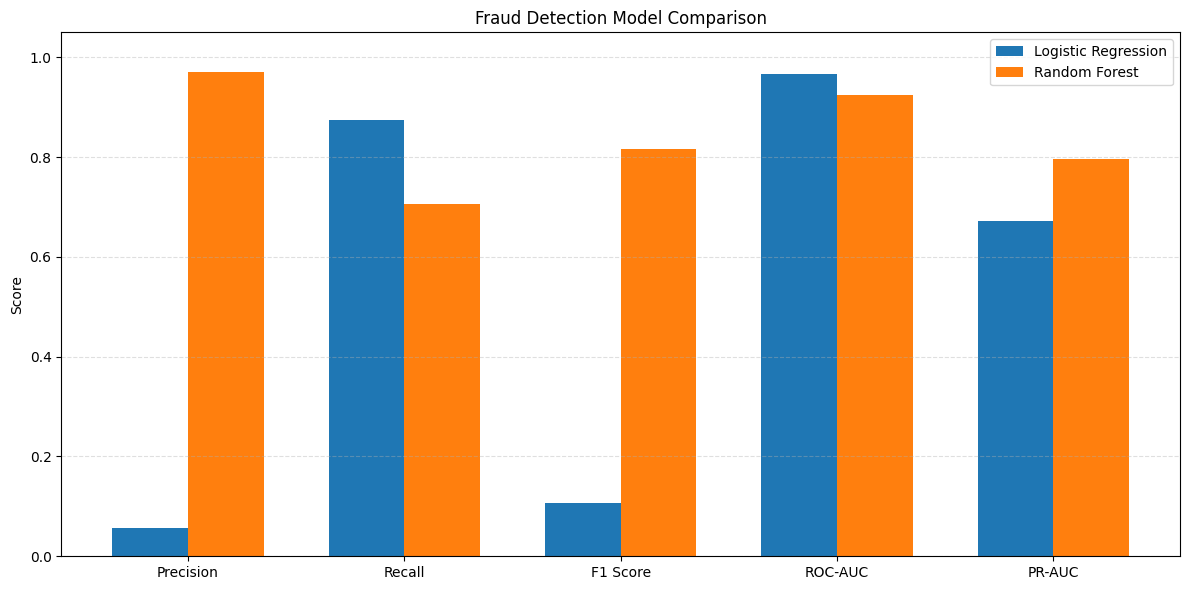

In [8]:

# STEP 7: VISUALIZE MODEL COMPARISON

import matplotlib.pyplot as plt
import numpy as np

metrics = ["Precision", "Recall", "F1 Score", "ROC-AUC", "PR-AUC"]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width/2,
    results.loc[0, metrics].values.astype(float),
    width,
    label="Logistic Regression"
)

plt.bar(
    x + width/2,
    results.loc[1, metrics].values.astype(float),
    width,
    label="Random Forest"
)

plt.xticks(x, metrics)
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("Fraud Detection Model Comparison")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


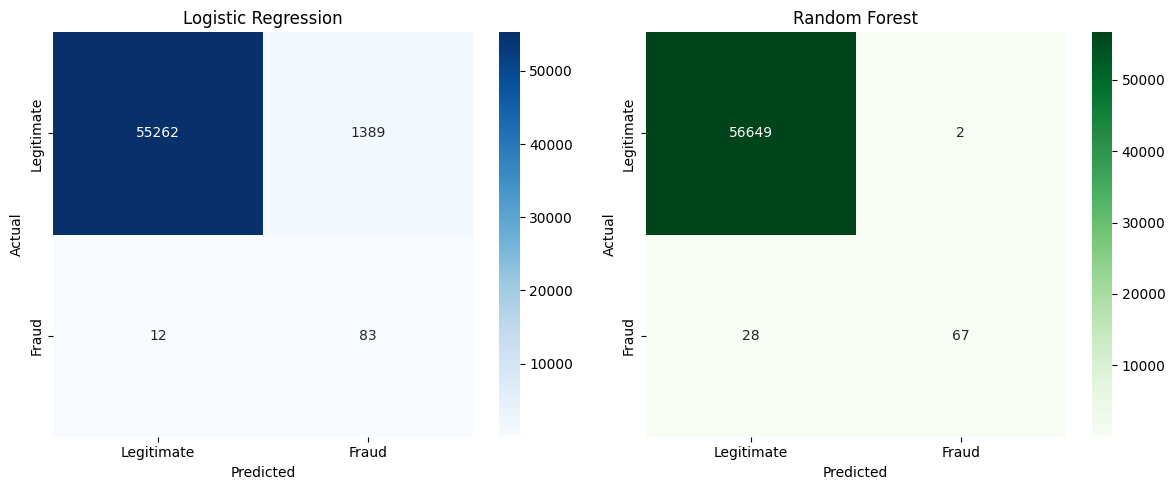

In [9]:

# STEP 8: CONFUSION MATRIX VISUALIZATION

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression
cm_lr = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"],
    ax=axes[0]
)
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"],
    ax=axes[1]
)
axes[1].set_title("Random Forest")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()


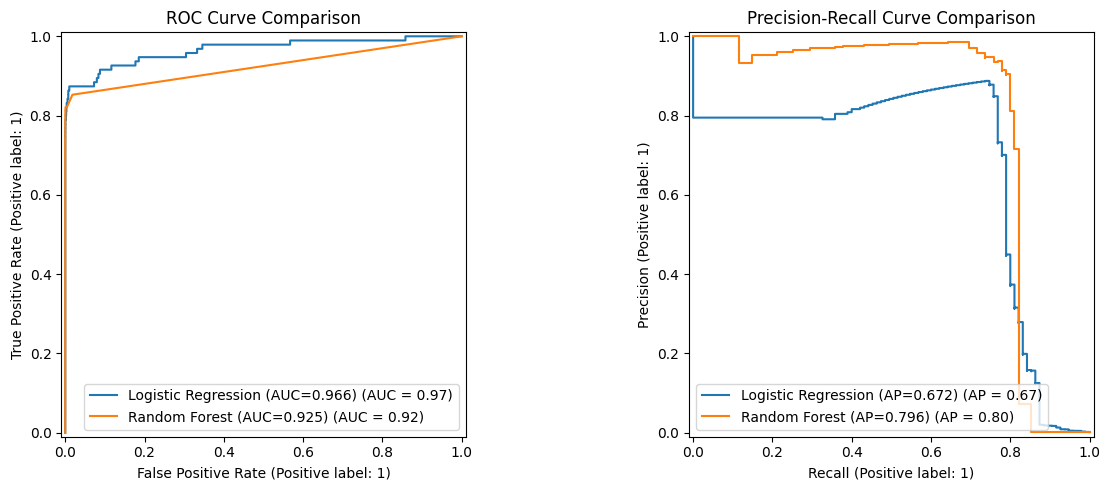

In [10]:

# STEP 9: ROC AND PRECISION-RECALL CURVES

import matplotlib.pyplot as plt
from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay,
    roc_auc_score,
    average_precision_score
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ROC curves
RocCurveDisplay.from_predictions(
    y_test, y_prob_lr,
    name=f"Logistic Regression (AUC={roc_auc_score(y_test, y_prob_lr):.3f})",
    ax=axes[0]
)

RocCurveDisplay.from_predictions(
    y_test, y_prob_rf,
    name=f"Random Forest (AUC={roc_auc_score(y_test, y_prob_rf):.3f})",
    ax=axes[0]
)

axes[0].set_title("ROC Curve Comparison")

# Precision-Recall curves
PrecisionRecallDisplay.from_predictions(
    y_test, y_prob_lr,
    name=f"Logistic Regression (AP={average_precision_score(y_test, y_prob_lr):.3f})",
    ax=axes[1]
)

PrecisionRecallDisplay.from_predictions(
    y_test, y_prob_rf,
    name=f"Random Forest (AP={average_precision_score(y_test, y_prob_rf):.3f})",
    ax=axes[1]
)

axes[1].set_title("Precision-Recall Curve Comparison")

plt.tight_layout()
plt.show()



## Conclusion

This project developed and evaluated machine-learning models for detecting fraudulent credit card transactions using the Credit Card Fraud Detection dataset from Kaggle.

Two classification algorithms were evaluated: Logistic Regression and Random Forest. Their performance was assessed using precision, recall, F1-score, ROC-AUC, average precision, and confusion matrices.

Logistic Regression achieved a ROC-AUC of 0.966 and detected 83 of the 95 fraudulent transactions in the test set. Random Forest achieved a ROC-AUC of 0.925 and an average precision of 0.796, detecting 67 fraudulent transactions while producing only 2 false-positive alerts.

The results demonstrate that model selection depends on the operational objective. Logistic Regression detected more fraud at the default threshold, whereas Random Forest produced fewer false alarms. Further threshold tuning and validation would help balance fraud detection against unnecessary alerts.

**Student:** Mohammed Afnan Saad
